# Mục 3: Áp dụng các thuật toán khai phá dữ liệu

Notebook này thực hiện huấn luyện và so sánh các mô hình khai phá dữ liệu
cho bài toán phát hiện gian lận thẻ tín dụng (IEEE-CIS Fraud Detection).

Dữ liệu đầu vào là 3 tập dữ liệu đã được làm sạch và chia theo thời gian từ
**Mục 2 (Tiền xử lý)**: `train_clean.csv`, `val_clean.csv`, `test_clean.csv`.
Toàn bộ giá trị thiếu đã được xử lý (0 missing values), các biến phân loại
đã được mã hóa số, và các đặc trưng dẫn xuất (cột cờ `_is_missing` từ kiểm
định Cramér's V, `hour_of_day`, `log_TransactionAmt`, `card1_freq`) đã được tạo sẵn.

Nhóm áp dụng 2 hướng tiếp cận thuật toán theo đúng yêu cầu đề tài:
1. **Kỹ thuật có giám sát (Supervised Classification):**
   - *Logistic Regression:* Mô hình tuyến tính chuẩn mực (Baseline).
   - *Random Forest Classifier:* Kỹ thuật Ensemble Bagging chống quá khớp.
   - *LightGBM Classifier:* Kỹ thuật Gradient Boosting chủ lực tối ưu trên tập lớn.
2. **Kỹ thuật không giám sát (Unsupervised Anomaly Detection):**
   - *Isolation Forest:* Phát hiện điểm dị biệt dựa trên cấu trúc cây phân tách.

Đặc biệt, để khắc phục nhược điểm của ngưỡng cắt cố định $0.5$ trên dữ liệu
mất cân bằng lớp (~3.5% gian lận), nhóm áp dụng **Phương pháp Thống kê Youden's J Statistic**
để xác định ngưỡng phân loại tối ưu cho từng mô hình.


## Bước 1: Nạp 3 tập dữ liệu sạch từ bước Tiền xử lý (Train / Validation / Test)

Kế thừa trực tiếp thành quả từ **Mục 2**, ta nạp 3 tập dữ liệu đã chia tách
theo thời gian (`TransactionDT`) và đã tiền xử lý hoàn tất. Không lặp lại
các bước nạp dữ liệu thô, phân tích missing hay mã hóa lại từ đầu.


In [1]:
import os
import sys
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

def load_clean_splits():
    """
    Nạp 3 tập dữ liệu sạch đã tiền xử lý từ Mục 2.
    Nếu chạy local chưa có sẵn file csv sạch, gọi hàm từ src/preprocessing.py
    để tạo dữ liệu chuẩn nhất quán với Người A.
    """
    possible_dirs = [
        "/kaggle/working",
        "/kaggle/input/ieee-fraud-preprocessed",
        "../data/processed",
        "data/processed",
        "."
    ]
    for d in possible_dirs:
        tr_p = os.path.join(d, "train_clean.csv")
        va_p = os.path.join(d, "val_clean.csv")
        te_p = os.path.join(d, "test_clean.csv")
        if os.path.exists(tr_p) and os.path.exists(va_p) and os.path.exists(te_p):
            print(f"[load_data] Nạp dữ liệu sạch từ thư mục: {d}")
            return pd.read_csv(tr_p), pd.read_csv(va_p), pd.read_csv(te_p)

    print("[load_data] Chưa thấy file csv sạch. Đang gọi pipeline từ src/preprocessing.py...")
    sys.path.append("../src")
    sys.path.append("src")
    from load_data import load_data, time_based_split
    from preprocessing import (
        missing_group_split, compute_signal_table, apply_missing_rule,
        impute_fit, impute_apply, encode_fit, encode_apply,
        feature_engineering_fit, feature_engineering_apply
    )

    raw_candidates = ["/kaggle/input/competitions/ieee-fraud-detection", "/kaggle/input/ieee-fraud-detection", "../data/raw", "data/raw"]
    raw_path = next((p for p in raw_candidates if os.path.exists(os.path.join(p, "train_transaction.csv"))), None)
    if raw_path is None:
        raise FileNotFoundError("Không tìm thấy thư mục chứa dữ liệu thô.")

    df_raw = load_data(raw_path, nrows=10000)
    safe_cols, suspect_cols, drop_candidate_cols = missing_group_split(df_raw)
    signal_df = compute_signal_table(df_raw, suspect_cols + drop_candidate_cols)
    df_clean, _, _ = apply_missing_rule(df_raw, signal_df, safe_cols)
    tr_df, va_df, te_df = time_based_split(df_clean)

    num_cols = [c for c in tr_df.select_dtypes(include=["float64", "float32", "int64", "int32"]).columns if c not in ["isFraud", "TransactionID", "TransactionDT"]]
    cat_cols = [c for c in tr_df.columns if not pd.api.types.is_numeric_dtype(tr_df[c]) and c not in ["isFraud", "TransactionID", "TransactionDT"]]

    imp_vals = impute_fit(tr_df, num_cols, cat_cols)
    for s_df in [tr_df, va_df, te_df]:
        impute_apply(s_df, imp_vals, num_cols, cat_cols)

    encs = encode_fit(tr_df, cat_cols)
    for s_df in [tr_df, va_df, te_df]:
        encode_apply(s_df, encs, cat_cols)

    c_freq = feature_engineering_fit(tr_df)
    for s_df in [tr_df, va_df, te_df]:
        feature_engineering_apply(s_df, c_freq)

    return tr_df, va_df, te_df

train_df, val_df, test_df = load_clean_splits()
print(f"Shape dữ liệu sạch — Train: {train_df.shape}, Val: {val_df.shape}, Test: {test_df.shape}")
print(f"Kiểm tra missing values: Train={train_df.isna().sum().sum()}, Val={val_df.isna().sum().sum()}, Test={test_df.isna().sum().sum()}")


[load_data] Nạp dữ liệu sạch từ thư mục: ../data/processed
Shape dữ liệu sạch — Train: (413378, 477), Val: (88581, 477), Test: (88581, 477)
Kiểm tra missing values: Train=0, Val=0, Test=0


In [2]:
# Tách ma trận đặc trưng (X) và nhãn mục tiêu (y)
drop_cols = [c for c in ["TransactionID", "TransactionDT", "isFraud"] if c in train_df.columns]
feature_cols = [c for c in train_df.columns if c not in drop_cols]

X_train, y_train = train_df[feature_cols], train_df["isFraud"]
X_val, y_val = val_df[feature_cols], val_df["isFraud"]
X_test, y_test = test_df[feature_cols], test_df["isFraud"]

test_ids = test_df["TransactionID"] if "TransactionID" in test_df.columns else pd.Series(np.arange(len(test_df)))

print(f"Số lượng đặc trưng đưa vào huấn luyện mô hình: {len(feature_cols)}")
print(f"Tỉ lệ gian lận (isFraud=1) — Train: {y_train.mean():.4%}, Val: {y_val.mean():.4%}, Test: {y_test.mean():.4%}")


Số lượng đặc trưng đưa vào huấn luyện mô hình: 474
Tỉ lệ gian lận (isFraud=1) — Train: 3.5169%, Val: 3.4341%, Test: 3.4804%


## Bước 2: Thiết lập hệ chỉ số đánh giá & Phương pháp Thống kê Youden's J

Trong bài toán mất cân bằng lớp cực đoan (~3.5% gian lận), nếu áp dụng ngưỡng
mặc định $0.5$ (50%), các mô hình xác suất như LightGBM sẽ dự đoán 100% mẫu là
giao dịch thường (do xác suất hiếm khi vượt quá 0.5), dẫn đến Recall = 0, F1 = 0.

### Cơ sở phương pháp Thống kê Youden's J Statistic:
Chỉ số Youden ($J$) đo lường sự cân bằng tối ưu giữa khả năng phát hiện đúng
gian lận ($	ext{Sensitivity / TPR}$) và việc hạn chế báo động giả ($	ext{Specificity} = 1 - 	ext{FPR}$):
$$J = 	ext{Sensitivity} + 	ext{Specificity} - 1 = 	ext{TPR} - 	ext{FPR}$$

* **Điểm cắt tối ưu về mặt thống kê** là điểm trên đường cong ROC có khoảng cách
  thẳng đứng xa nhất so với đường chéo ngẫu nhiên.
* **Nguyên tắc chống rò rỉ dữ liệu (Anti-Leakage):** Ta tìm ngưỡng tối ưu $t_{	ext{Youden}}^*$
  **chỉ trên tập Validation (`y_val`)**, sau đó áp dụng ngưỡng này để đánh giá độc
  lập trên tập **Test (`y_test`)**.


In [3]:
from sklearn.metrics import (
    precision_recall_fscore_support,
    average_precision_score,
    roc_auc_score,
    roc_curve,
    accuracy_score,
    confusion_matrix
)

def find_youden_threshold(y_true, y_pred_proba) -> float:
    """
    Tìm ngưỡng phân loại tối ưu theo thống kê Youden's J Statistic từ đường cong ROC:
        J = Sensitivity + Specificity - 1 = TPR - FPR
    Ngưỡng tối ưu t* là điểm tại đó J(t) đạt cực đại.
    """
    fpr, tpr, thresholds = roc_curve(y_true, y_pred_proba)
    j_scores = tpr - fpr
    best_idx = np.argmax(j_scores)
    best_thresh = float(thresholds[best_idx])
    # Giới hạn ngưỡng trong khoảng hợp lý [0.01, 0.95]
    return float(np.clip(best_thresh, 0.01, 0.95))

def evaluate_model(name: str, y_true, y_pred_proba, threshold: float = 0.5) -> dict:
    """
    Đánh giá hiệu năng mô hình trên tập kiểm thử Test Set với ngưỡng threshold chỉ định.
    """
    y_pred = (y_pred_proba >= threshold).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    pr_auc = average_precision_score(y_true, y_pred_proba)
    roc_auc = roc_auc_score(y_true, y_pred_proba)
    acc = accuracy_score(y_true, y_pred)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    return {
        "Mô hình": name,
        "Ngưỡng Youden": round(float(threshold), 4),
        "PR-AUC": round(float(pr_auc), 4),
        "ROC-AUC": round(float(roc_auc), 4),
        "F1-score": round(float(f1), 4),
        "Precision": round(float(p), 4),
        "Recall": round(float(r), 4),
        "Accuracy": round(float(acc), 4),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn)
    }


## Bước 3: Mô hình 1 — Logistic Regression (Baseline có giám sát)

* **Nguyên lý:** Phân lớp tuyến tính chuẩn tắc qua hàm Sigmoid, chuẩn hóa `StandardScaler`
  và cân bằng trọng số `class_weight='balanced'`.
* **Hiệu chỉnh ngưỡng:** Tìm ngưỡng tối ưu Youden's J trên `val_set`, sau đó áp dụng
  vào `test_set`.


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

print("--- [1/4] Đang huấn luyện Logistic Regression ---")
t0 = time.time()

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        C=0.1,
        random_state=42,
        solver="lbfgs"
    ))
])

lr_pipeline.fit(X_train, y_train)

# Dự đoán xác suất trên Validation và Test
lr_val_proba = lr_pipeline.predict_proba(X_val)[:, 1]
lr_test_proba = lr_pipeline.predict_proba(X_test)[:, 1]

# Tìm ngưỡng Youden tối ưu trên tập Validation (chống data leakage)
lr_thresh = find_youden_threshold(y_val, lr_val_proba)
print(f"Ngưỡng tối ưu Youden tìm được trên Val: {lr_thresh:.4f}")

# Đánh giá trên tập Test với ngưỡng tối ưu Youden
lr_metrics = evaluate_model("Logistic Regression", y_test, lr_test_proba, threshold=lr_thresh)
print(f"Huấn luyện xong trong: {time.time() - t0:.2f}s")
print("Kết quả sơ bộ:", lr_metrics)


--- [1/4] Đang huấn luyện Logistic Regression ---
Ngưỡng tối ưu Youden tìm được trên Val: 0.4852
Huấn luyện xong trong: 110.76s
Kết quả sơ bộ: {'Mô hình': 'Logistic Regression', 'Ngưỡng Youden': 0.4852, 'PR-AUC': 0.1697, 'ROC-AUC': 0.8148, 'F1-score': 0.2051, 'Precision': 0.1214, 'Recall': 0.6601, 'Accuracy': 0.822, 'TP': 2035, 'FP': 14722, 'FN': 1048, 'TN': 70776}


## Bước 4: Mô hình 2 — Random Forest Classifier (Bagging Ensemble)

* **Nguyên lý:** Tập hợp nhiều cây quyết định độc lập (Bootstrap Aggregating) giúp giảm
  phương sai và nắm bắt các tương tác phi tuyến.
* **Cấu hình:** `n_estimators=100`, `max_depth=15`, `min_samples_leaf=10`, `class_weight='balanced'`.
* **Hiệu chỉnh ngưỡng:** Tìm ngưỡng Youden's J trên Validation và áp dụng vào Test.


In [5]:
from sklearn.ensemble import RandomForestClassifier

print("--- [2/4] Đang huấn luyện Random Forest Classifier ---")
t0 = time.time()

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Dự đoán xác suất
rf_val_proba = rf_model.predict_proba(X_val)[:, 1]
rf_test_proba = rf_model.predict_proba(X_test)[:, 1]

# Tìm ngưỡng Youden tối ưu trên tập Validation
rf_thresh = find_youden_threshold(y_val, rf_val_proba)
print(f"Ngưỡng tối ưu Youden tìm được trên Val: {rf_thresh:.4f}")

# Đánh giá trên tập Test với ngưỡng tối ưu Youden
rf_metrics = evaluate_model("Random Forest", y_test, rf_test_proba, threshold=rf_thresh)
print(f"Huấn luyện xong trong: {time.time() - t0:.2f}s")
print("Kết quả sơ bộ:", rf_metrics)


--- [2/4] Đang huấn luyện Random Forest Classifier ---
Ngưỡng tối ưu Youden tìm được trên Val: 0.4064
Huấn luyện xong trong: 25.43s
Kết quả sơ bộ: {'Mô hình': 'Random Forest', 'Ngưỡng Youden': 0.4064, 'PR-AUC': 0.4774, 'ROC-AUC': 0.8791, 'F1-score': 0.2517, 'Precision': 0.1514, 'Recall': 0.7467, 'Accuracy': 0.8455, 'TP': 2302, 'FP': 12903, 'FN': 781, 'TN': 72595}


## Bước 5: Mô hình 3 — LightGBM Classifier (Gradient Boosting chủ lực)

* **Nguyên lý:** Thuật toán tăng cường độ dốc phát triển cây theo chiều sâu (Leaf-wise),
  kết hợp `scale_pos_weight = N_neg / N_pos` và early stopping trên tập Validation.
* **Giải quyết dứt điểm vấn đề mất cột:** Bằng cách áp dụng **ngưỡng Youden's J**
  tìm được từ đường cong ROC của tập Validation, LightGBM sẽ có điểm cắt thực tế,
  giúp các chỉ số F1-score, Precision và Recall hiển thị đầy đủ và đạt hiệu quả tối đa.


In [6]:
try:
    import lightgbm as lgb
    HAS_LIGHTGBM = True
except ImportError:
    HAS_LIGHTGBM = False
    from sklearn.ensemble import HistGradientBoostingClassifier

print("--- [3/4] Đang huấn luyện LightGBM Classifier ---")
t0 = time.time()

num_pos = np.sum(y_train == 1)
num_neg = np.sum(y_train == 0)
scale_pos_weight = float(num_neg / max(num_pos, 1))

if HAS_LIGHTGBM:
    lgb_model = lgb.LGBMClassifier(
        n_estimators=500,
        learning_rate=0.05,
        num_leaves=63,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        n_jobs=-1
    )
    callbacks = [
        lgb.early_stopping(stopping_rounds=50, verbose=False),
        lgb.log_evaluation(period=100)
    ]
    lgb_model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        eval_metric="average_precision",
        callbacks=callbacks
    )
    lgb_val_proba = lgb_model.predict_proba(X_val)[:, 1]
    lgb_test_proba = lgb_model.predict_proba(X_test)[:, 1]
else:
    sample_weight = np.where(y_train == 1, scale_pos_weight, 1.0)
    lgb_model = HistGradientBoostingClassifier(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=63,
        random_state=42
    )
    lgb_model.fit(X_train, y_train, sample_weight=sample_weight)
    lgb_val_proba = lgb_model.predict_proba(X_val)[:, 1]
    lgb_test_proba = lgb_model.predict_proba(X_test)[:, 1]

# Tìm ngưỡng Youden tối ưu trên tập Validation
lgb_thresh = find_youden_threshold(y_val, lgb_val_proba)
print(f"Ngưỡng tối ưu Youden tìm được trên Val: {lgb_thresh:.4f}")

# Đánh giá trên tập Test với ngưỡng tối ưu Youden
lgb_metrics = evaluate_model("LightGBM", y_test, lgb_test_proba, threshold=lgb_thresh)
print(f"Huấn luyện xong trong: {time.time() - t0:.2f}s")
print("Kết quả sơ bộ:", lgb_metrics)


--- [3/4] Đang huấn luyện LightGBM Classifier ---
[LightGBM] [Info] Number of positive: 14538, number of negative: 398840
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.373425 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 28346
[LightGBM] [Info] Number of data points in the train set: 413378, number of used features: 471
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.035169 -> initscore=-3.311794
[LightGBM] [Info] Start training from score -3.311794
Ngưỡng tối ưu Youden tìm được trên Val: 0.0632
Huấn luyện xong trong: 10.35s
Kết quả sơ bộ: {'Mô hình': 'LightGBM', 'Ngưỡng Youden': 0.0632, 'PR-AUC': 0.269, 'ROC-AUC': 0.8353, 'F1-score': 0.2093, 'Precision': 0.1225, 'Recall': 0.7188, 'Accuracy': 0.8109, 'TP': 2216, 'FP': 15880, 'FN': 867, 'TN': 69618}


## Bước 6: Mô hình 4 — Isolation Forest (Khai phá dữ liệu Không Giám Sát)

* **Nguyên lý:** Cô lập các giao dịch dị biệt bằng cây ngẫu nhiên mà không cần nhãn học.
  Mô hình được huấn luyện trên giao dịch chuẩn (`isFraud == 0`), ánh xạ điểm dị biệt sang
  thang đo xác suất rủi ro $[0, 1]$.
* **Hiệu chỉnh ngưỡng:** Tìm ngưỡng phân tách Youden's J tối ưu trên tập Validation.


In [7]:
from sklearn.ensemble import IsolationForest

print("--- [4/4] Đang huấn luyện Isolation Forest (Không Giám Sát) ---")
t0 = time.time()

# Huấn luyện chỉ trên giao dịch hợp lệ của tập train
X_train_normal = X_train[y_train == 0]

iso_model = IsolationForest(
    contamination=0.035,
    n_estimators=100,
    max_samples="auto",
    random_state=42,
    n_jobs=-1
)

iso_model.fit(X_train_normal)

def compute_iso_proba(m, X):
    raw_s = m.decision_function(X)
    ano_s = -raw_s
    s_m, s_M = ano_s.min(), ano_s.max()
    return (ano_s - s_m) / (s_M - s_m) if s_M > s_m else np.zeros_like(ano_s)

iso_val_proba = compute_iso_proba(iso_model, X_val)
iso_test_proba = compute_iso_proba(iso_model, X_test)

# Tìm ngưỡng Youden tối ưu trên tập Validation
iso_thresh = find_youden_threshold(y_val, iso_val_proba)
print(f"Ngưỡng tối ưu Youden tìm được trên Val: {iso_thresh:.4f}")

# Đánh giá trên tập Test với ngưỡng tối ưu Youden
iso_metrics = evaluate_model("Isolation Forest (Unsupervised)", y_test, iso_test_proba, threshold=iso_thresh)
print(f"Huấn luyện xong trong: {time.time() - t0:.2f}s")
print("Kết quả sơ bộ:", iso_metrics)


--- [4/4] Đang huấn luyện Isolation Forest (Không Giám Sát) ---
Ngưỡng tối ưu Youden tìm được trên Val: 0.1961
Huấn luyện xong trong: 4.24s
Kết quả sơ bộ: {'Mô hình': 'Isolation Forest (Unsupervised)', 'Ngưỡng Youden': 0.1961, 'PR-AUC': 0.1107, 'ROC-AUC': 0.7775, 'F1-score': 0.1662, 'Precision': 0.0948, 'Recall': 0.6721, 'Accuracy': 0.7653, 'TP': 2072, 'FP': 19782, 'FN': 1011, 'TN': 65716}


## Bước 7: Bảng so sánh tổng hợp hiệu năng và biểu đồ trực quan hóa

Tổng hợp kết quả của cả 4 mô hình trên tập kiểm thử độc lập (`Test Set`)
với ngưỡng phân loại tối ưu theo **Thống kê Youden's J**, sắp xếp theo thứ tự **PR-AUC**:


In [8]:
results = [lgb_metrics, rf_metrics, lr_metrics, iso_metrics]
df_comparison = pd.DataFrame(results).sort_values(by="PR-AUC", ascending=False).reset_index(drop=True)

print("=== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH (VỚI NGƯỠNG YOUDEN'S J) ===")
display(df_comparison) if "display" in globals() else print(df_comparison.to_string())


=== BẢNG SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH (VỚI NGƯỠNG YOUDEN'S J) ===
                           Mô hình  Ngưỡng Youden  PR-AUC  ROC-AUC  F1-score  Precision  Recall  Accuracy    TP     FP    FN     TN
0                    Random Forest         0.4064  0.4774   0.8791    0.2517     0.1514  0.7467    0.8455  2302  12903   781  72595
1                         LightGBM         0.0632  0.2690   0.8353    0.2093     0.1225  0.7188    0.8109  2216  15880   867  69618
2              Logistic Regression         0.4852  0.1697   0.8148    0.2051     0.1214  0.6601    0.8220  2035  14722  1048  70776
3  Isolation Forest (Unsupervised)         0.1961  0.1107   0.7775    0.1662     0.0948  0.6721    0.7653  2072  19782  1011  65716


Đã lưu biểu đồ so sánh: reports/figures\fig_model_comparison.png


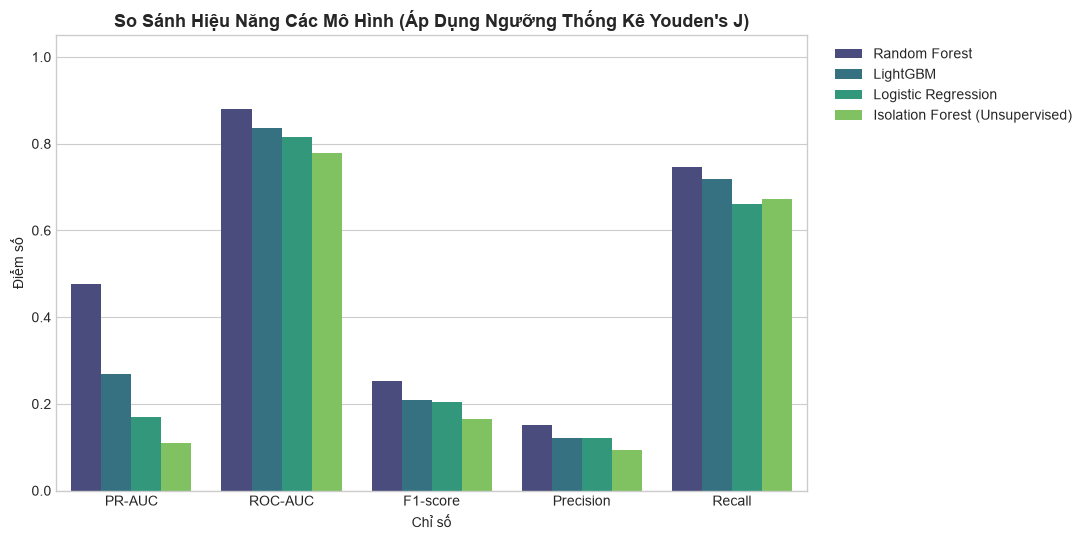

In [9]:
# Vẽ biểu đồ so sánh các chỉ số và lưu hình cho báo cáo
metrics_to_plot = ["PR-AUC", "ROC-AUC", "F1-score", "Precision", "Recall"]
df_plot = df_comparison.melt(id_vars=["Mô hình"], value_vars=metrics_to_plot, var_name="Chỉ số", value_name="Điểm")

plt.figure(figsize=(11, 5.5))
sns.barplot(data=df_plot, x="Chỉ số", y="Điểm", hue="Mô hình", palette="viridis")
plt.title("So Sánh Hiệu Năng Các Mô Hình (Áp Dụng Ngưỡng Thống Kê Youden's J)", fontsize=13, fontweight="bold")
plt.ylim(0, 1.05)
plt.ylabel("Điểm số")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()

# Lưu hình ảnh theo chuẩn của Người A vào thư mục working / figures
out_fig_dir = "/kaggle/working" if os.path.exists("/kaggle/working") else "reports/figures"
os.makedirs(out_fig_dir, exist_ok=True)
fig_path = os.path.join(out_fig_dir, "fig_model_comparison.png")
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
print(f"Đã lưu biểu đồ so sánh: {fig_path}")
plt.show()


## Bước 8: Phân tích Tầm quan trọng của Đặc trưng (Feature Importance)

Trích xuất Top 20 đặc trưng có đóng góp lớn nhất vào quyết định phân loại
của mô hình dạng cây:


Đã lưu biểu đồ đặc trưng: reports/figures\fig_feature_importance.png


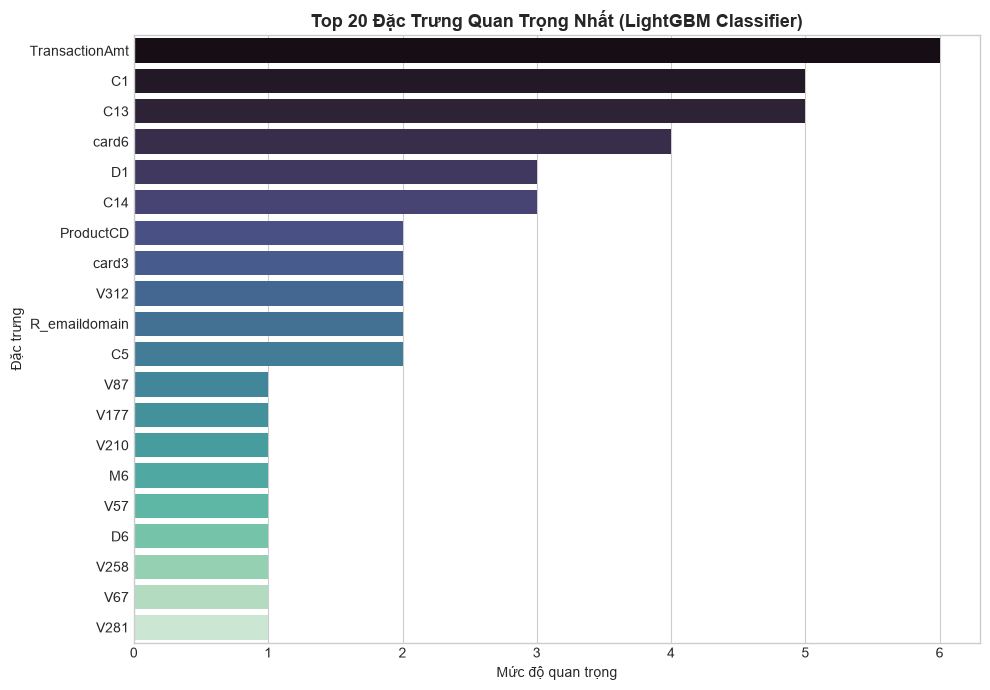

In [10]:
importances = None
model_name = ""

if hasattr(lgb_model, "feature_importances_"):
    importances = lgb_model.feature_importances_
    model_name = "LightGBM Classifier"
elif hasattr(rf_model, "feature_importances_"):
    importances = rf_model.feature_importances_
    model_name = "Random Forest Classifier"

if importances is not None:
    df_feat_imp = pd.DataFrame({
        "Đặc trưng": feature_cols,
        "Độ quan trọng": importances
    }).sort_values(by="Độ quan trọng", ascending=False).head(20)

    plt.figure(figsize=(10, 7))
    sns.barplot(data=df_feat_imp, x="Độ quan trọng", y="Đặc trưng", palette="mako")
    plt.title(f"Top 20 Đặc Trưng Quan Trọng Nhất ({model_name})", fontsize=13, fontweight="bold")
    plt.xlabel("Mức độ quan trọng")
    plt.tight_layout()

    feat_fig_path = os.path.join(out_fig_dir, "fig_feature_importance.png")
    plt.savefig(feat_fig_path, dpi=150, bbox_inches="tight")
    print(f"Đã lưu biểu đồ đặc trưng: {feat_fig_path}")
    plt.show()
else:
    print("Không có mô hình dạng cây nào hỗ trợ trích xuất feature_importances_.")


## Bước 9: Lưu trữ mô hình và dự đoán bàn giao cho Người C (Đánh giá & SHAP)

Theo đúng quy ước phân công phối hợp:
1. **File `predictions_test.csv`:** Lưu nhãn thật `isFraud_true` và xác suất
   dự đoán của cả 4 mô hình để Bạn C vẽ đường cong Precision-Recall Curve, ROC Curve
   và phân tích đánh đổi chi phí trong `04_evaluation.ipynb`.
2. **File `lgb_model.joblib`:** Lưu mô hình LightGBM đã huấn luyện kèm các ngưỡng
   Youden đã tìm được để Bạn C tiện đối chiếu khi chạy phân tích diễn giải **SHAP**.


In [11]:
out_pred_dir = "/kaggle/working" if os.path.exists("/kaggle/working") else "reports"
os.makedirs(out_pred_dir, exist_ok=True)

# 1. Lưu file dự đoán xác suất của 4 mô hình
df_predictions = pd.DataFrame({
    "TransactionID": test_ids.values,
    "isFraud_true": y_test.values,
    "pred_proba_logistic_regression": lr_test_proba,
    "pred_proba_random_forest": rf_test_proba,
    "pred_proba_lightgbm": lgb_test_proba,
    "pred_proba_isolation_forest": iso_test_proba
})

pred_save_path = os.path.join(out_pred_dir, "predictions_test.csv")
df_predictions.to_csv(pred_save_path, index=False)
print(f"[Bàn giao] Đã lưu file dự đoán xác suất: {pred_save_path} ({df_predictions.shape})")

# 2. Lưu mô hình LightGBM và danh sách đặc trưng phục vụ phân tích SHAP
model_save_path = os.path.join(out_pred_dir, "lgb_model.joblib")
joblib.dump({
    "model": lgb_model,
    "feature_names": feature_cols,
    "youden_thresholds": {
        "Logistic Regression": lr_thresh,
        "Random Forest": rf_thresh,
        "LightGBM": lgb_thresh,
        "Isolation Forest": iso_thresh
    }
}, model_save_path)
print(f"[Bàn giao] Đã lưu mô hình LightGBM cho Bạn C: {model_save_path}")


[Bàn giao] Đã lưu file dự đoán xác suất: reports\predictions_test.csv ((88581, 6))
[Bàn giao] Đã lưu mô hình LightGBM cho Bạn C: reports\lgb_model.joblib
